# Stage A: distilling a speech teacher into a chip-sized student

**What Stage A decides (before the Tiny Tapeout shuttle closes, ~2026-11-30):** what the silicon
freezes. The network weights live in QSPI flash and can be retrained after tapeout, so Stage A
has to settle the front end (bands, filter order, hop, bit widths), what the engine runs (layer
types, weight precision, output stride, where state lives) and show the best students fit the
16-tile budget. Detector heads (Stage B) come later.

**Method.** A teacher (a pretrained speech model) turns audio into a vector every 80 ms. The
student sees only the chip's filterbank output and learns to produce the same vector at the
same instant. Training audio is simulated only; selection uses **real** recordings (no labels
needed: teacher and student just hear the same audio).

**Metric.** Cosine between student and teacher vectors on speech-active steps:
* `real_val`: AMI far-field meetings + LibriSpeech dev-clean + MUSAN speech (selection)
* `sim_val`: 66-word clips, held-out voices in the simulator's test mixer (reported)
* `real_test`: disjoint real recordings, read once per finalist (not in this notebook yet)

Cosines are only comparable between runs with the same teacher. `word_acc` (66-word accuracy
of the A0 probe head trained on the student's outputs) is comparable across teachers.

**Files.** Search space: `model/search_space.py`. Runner: `model/stage_a.py` (resumable; the GPU
is shared). Students: `model/students.py`. Every finished run is one line in
`research/stage_a/ledger.jsonl`; this notebook reads only that and
`data/probe/results/teachers.json`.

| Step | Question | Varies |
|---|---|---|
| A0 | Which teacher? | teacher (frozen) on the 66-word test |
| A1 | Which front end? | bands x filter order (+ hop), fixed 50k TCN |
| A2 | Which layer types must the engine run? | architecture families at 2 sizes |
| A3 | How big? | size ladder x stride for the top 2 families |
| A4 | 8-bit or 4-bit weights? | precision at equal QSPI bytes |
| A5 | Best distillation recipe | optimizer, loss, data, clean-teacher option |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "research" else Path.cwd()
LEDGER = ROOT / "research/stage_a/ledger.jsonl"
TEACH = ROOT / "data/probe/results/teachers.json"
pd.set_option("display.width", 200)


def ledger():
    rows = [json.loads(l) for l in LEDGER.read_text().splitlines() if l.strip()] if LEDGER.exists() else []
    out = []
    for r in rows:
        c, b = r.get("config", {}), r.get("best") or {}
        out.append({"name": r.get("name"), "group": r.get("group"), "status": r.get("status"), "family": c.get("family"),
                    "size": c.get("size"), "params": r.get("params"), "bands": c.get("bands"), "order": c.get("order"),
                    "hop_ms": c.get("hop_ms"), "stride": c.get("stride"), "teacher": c.get("teacher"),
                    "frontend_ff": r.get("frontend_ff"), "cycles": r.get("cycles_per_sample"),
                    "word_acc": b.get("word_acc"), "real_cos": b.get("real_val_cos"), "sim_cos": b.get("sim_val_cos"),
                    "ami": b.get("real_val_cos_ami"), "libri": b.get("real_val_cos_libri"), "musan": b.get("real_val_cos_musan"),
                    "best_step": b.get("step"), "steps": r.get("steps"), "wall_min": round((r.get("wall_s") or 0) / 60, 1)})
    return pd.DataFrame(out)


L = ledger()
print(f"{len(L)} runs in the ledger")

51 runs in the ledger


## A0: which teacher?

Each teacher frozen, the same small head, 66-way word classification on held-out voices
(`model/probe_teachers.py`). `acc_pca96` is the teacher reduced to 96 dimensions, which is
about what a student can afford to reproduce (a 768-d output layer alone would cost ~50k
parameters). For reference: our TCN trained from scratch on chip features scores 52-55% on
the same test (research/06_probes, F2).

**Decision (2026-10-28): keep Google's speech_embedding.** Whisper-tiny layer 4 is the best
teacher on its own at 96 dims (68.3%, encoder fed the 1.6 s window only; `model/teach_export.py`),
but the same 50k TCN student copies it worse:

| teacher | teacher acc | student word_acc |
|---|---|---|
| speech_embedding | 61.1% | 52.3% |
| whisper_tiny L4 (bidirectional over the window) | 68.3% | 51.5% |
| whisper_tiny L4 causal (audio up to each step only) | 64.5% | 49.8% |

Whisper's lead comes from audio after the target step (bidirectional) and from features a
50k causal student cannot reproduce; speech_embedding was built small and causal.

In [2]:
if TEACH.exists():
    T = pd.DataFrame([{"teacher": k, **{x: v.get(x) for x in ("dims", "acc_full", "acc_pca96", "params", "license")}}
                      for k, v in json.loads(TEACH.read_text()).items()]).sort_values("acc_pca96", ascending=False)
    display(T)

,teacher,dims,acc_full,acc_pca96,params,license
16,whisper_base/L6,512,0.7187,0.7066,20M enc,MIT
22,whisper_tiny/L4,384,0.7028,0.6960,8M enc,MIT
15,whisper_base/L4,512,0.7082,0.6877,20M enc,MIT
0,speech_embedding,96,0.6111,0.6111,~1.3M,None
21,whisper_tiny/L2,384,0.6394,0.6100,8M enc,MIT
11,w2v2_phoneme/L16,1024,0.6358,0.5986,315M,Apache-2.0
9,w2v2_phoneme/L8,1024,0.6389,0.5906,315M,Apache-2.0
10,w2v2_phoneme/L12,1024,0.6353,0.5898,315M,Apache-2.0
12,w2v2_phoneme/L20,1024,0.6226,0.5866,315M,Apache-2.0
14,whisper_base/L2,512,0.6223,0.5764,20M enc,MIT


## A1: front end

Same student (50k-param TCN, 6,000 steps), same teacher, front end varied. The x axis is
filterbank flip-flops (`frontend_var.flipflops`; 320 FF is about one tile).

,name,status,teacher,bands,order,hop_ms,frontend_ff,cycles,params,word_acc,real_cos,sim_cos,ami,libri,musan,best_step,wall_min
2,A1 b12 o4 h16 tcn50k,done,whisper_tiny_L4,12,4,16,1248,722,49124,0.5147,0.4628,0.4932,0.4439,0.4797,0.4636,6000,15.7


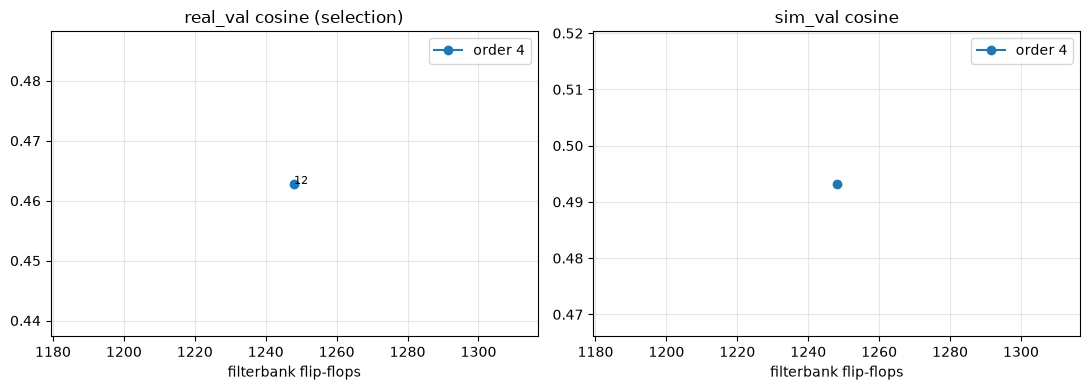

In [3]:
A1 = L[(L.group == "A1") & (L.teacher != "speech_embedding")].sort_values(["order", "bands"])
if len(A1):
    display(A1[["name", "status", "teacher", "bands", "order", "hop_ms", "frontend_ff", "cycles", "params", "word_acc", "real_cos", "sim_cos",
                "ami", "libri", "musan", "best_step", "wall_min"]])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for o, g in A1[A1.hop_ms == 16].groupby("order"):
        ax[0].plot(g.frontend_ff, g.real_cos, "o-", label=f"order {o}")
        ax[1].plot(g.frontend_ff, g.sim_cos, "o-", label=f"order {o}")
        for _, r in g.iterrows():
            ax[0].annotate(int(r.bands), (r.frontend_ff, r.real_cos), fontsize=8)
    for a, t in zip(ax, ("real_val cosine (selection)", "sim_val cosine")):
        a.set_xlabel("filterbank flip-flops")
        a.set_title(t)
        a.grid(alpha=0.3)
        a.legend()
    plt.tight_layout()

## All runs

In [4]:
display(L)

,name,group,status,family,size,params,bands,order,hop_ms,stride,...,cycles,word_acc,real_cos,sim_cos,ami,libri,musan,best_step,steps,wall_min
0,A1 b12 o4 h16 tcn50k,A1,done,tcn,50000,49124,12,4,16,2,...,722,0.5228,0.6523,0.6942,0.6780,0.6313,0.6472,6000,6000,44.0
1,A1 b16 o4 h16 tcn50k,A1,done,tcn,50000,49668,16,4,16,2,...,962,0.5361,0.6608,0.7047,0.6891,0.6388,0.6529,6000,6000,28.7
2,A1 b12 o4 h16 tcn50k,A1,done,tcn,50000,49124,12,4,16,2,...,722,0.5147,0.4628,0.4932,0.4439,0.4797,0.4636,6000,6000,15.7
3,A1 b12 o4 h32 tcn50k,A1,done,tcn,50000,49569,12,4,32,2,...,722,0.5167,0.6530,0.6926,0.6776,0.6329,0.6480,6000,6000,34.5
4,A1 b8 o4 h16 tcn50k,A1,done,tcn,50000,49845,8,4,16,2,...,482,0.4973,0.6254,0.6653,0.6471,0.6064,0.6238,6000,6000,22.2
5,A0 whisper_tiny_L4_causal b12 o4 tcn50k,A0,done,tcn,50000,49124,12,4,16,2,...,722,0.4980,0.4930,0.5041,0.4717,0.5115,0.4946,5500,6000,13.9
6,A1 b24 o4 h16 tcn50k,A1,done,tcn,50000,49475,24,4,16,2,...,1442,0.5464,0.6605,0.7086,0.6908,0.6372,0.6517,6000,6000,14.0
7,A1 b10 o4 h16 tcn50k,A1,done,tcn,50000,48852,10,4,16,2,...,602,0.5160,0.6424,0.6843,0.6648,0.6241,0.6382,6000,6000,14.8
8,A1 b14 o4 h16 tcn50k,A1,done,tcn,50000,49396,14,4,16,2,...,842,0.5280,0.6557,0.6987,0.6842,0.6330,0.6490,6000,6000,14.3
9,A1 b20 o4 h16 tcn50k,A1,done,tcn,50000,48939,20,4,16,2,...,1202,0.5333,0.6563,0.7037,0.6861,0.6327,0.6485,6000,6000,18.2


## The SMAC3 study (from 2026-10-28)

The A2 grid was stopped (about a fifth done) in favour of one optimizer over everything:
`model/stage_a_smac.py`. SMAC3 (random forest over the conditional space, Hyperband over
training steps 1000 -> 3000 -> 9000) picks bands, hop, weight bits, stride, family + knobs,
teacher (Google's speech_embedding, Whisper-tiny L4, causal Whisper) and the training settings.
The size is not searched: each trial is the largest network that fits the chip's QSPI bus, MAC
and tile budgets, so every trial is a valid chip. Objective: `word_acc` (comparable across
teachers); `real_cos` (real recordings vs that trial's teacher) is the sim-to-real check.
Seeds are not fixed; every 10 trials the incumbent is re-run with a fresh seed (`repeat`
rows), which measures the noise.

3 trials, 2 trained; status counts: {'ok': 2, 'rf_too_short': 1}


,n,kind,budget,word_acc,real_val_cos,sim_val_cos,c.family,c.bands,c.hop_ms,c.stride,c.weight_bits,c.teacher,params,bus_bytes_per_step,macs_per_step,frontend_ff,wall_s,knobs
1,1,trial,1000,0.4173,0.4626,0.5220,ssm,14,16,4,8,speech_embedding,222750,230550,219816,1432,29.0,"{'conv_k': 4, 'expand': 1, 'kind': 'mingru', '..."
0,0,trial,1000,0.2233,0.2645,0.3029,transformer,12,16,1,8,whisper_tiny_L4,38310,59214,67080,1248,72.0,"{'attn': 'softmax', 'conv_module': True, 'ffn_..."


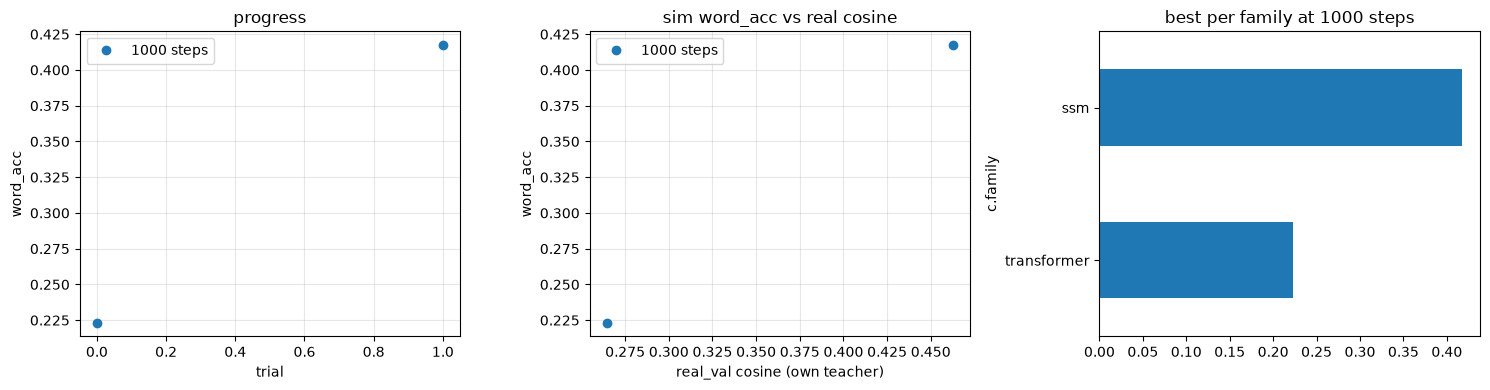

In [5]:
JS = ROOT / "research/stage_a/smac_trials.jsonl"
J = pd.DataFrame([{**{k: v for k, v in r.items() if k != "config"}, **{f"c.{k}": v for k, v in r["config"].items() if k != "knobs"},
                   "knobs": r["config"].get("knobs")} for r in map(json.loads, JS.read_text().splitlines())]) if JS.exists() else pd.DataFrame()
if len(J):
    ok = J[J.status == "ok"]
    print(f"{len(J)} trials, {len(ok)} trained; status counts:", J.status.value_counts().to_dict())
    rep = ok[ok.kind == "repeat"].word_acc
    if len(rep) > 1:
        print(f"noise: word_acc sd of incumbent repeats = {rep.std():.4f} (n={len(rep)})")
    cols = ["n", "kind", "budget", "word_acc", "real_val_cos", "sim_val_cos", "c.family", "c.bands", "c.hop_ms", "c.stride",
            "c.weight_bits", "c.teacher", "params", "bus_bytes_per_step", "macs_per_step", "frontend_ff", "wall_s", "knobs"]
    display(ok.sort_values("word_acc", ascending=False)[cols].head(20))
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for b, g in ok.groupby("budget"):
        ax[0].plot(g.n, g.word_acc, "o", label=f"{int(b)} steps")
        ax[1].plot(g.real_val_cos, g.word_acc, "o", label=f"{int(b)} steps")
    ax[0].set(xlabel="trial", ylabel="word_acc", title="progress")
    ax[1].set(xlabel="real_val cosine (own teacher)", ylabel="word_acc", title="sim word_acc vs real cosine")
    best = ok[ok.budget == ok.budget.max()].groupby("c.family").word_acc.max().sort_values()
    best.plot.barh(ax=ax[2], title=f"best per family at {int(ok.budget.max())} steps")
    for a in ax[:2]:
        a.grid(alpha=0.3)
        a.legend()
    plt.tight_layout()